## NLP Setup

In [ ]:
import pandas as pd, numpy as np, re, time, matplotlib.pyplot as plt, seaborn as sns
from collections import Counter
import spacy
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
sns.set_style('whitegrid'); SEED = 42; np.random.seed(SEED)

## Task 1: Preprocessing and Exploratory Analysis
### 1.1 Load and inspect the data

In [ ]:
from google.colab import files
up = files.upload()   # upload Tweets.csv
df = pd.read_csv('Tweets.csv')[['airline_sentiment','negativereason','airline','text']].dropna(subset=['text'])
df = df.rename(columns={'airline_sentiment':'label'})
print(df.shape); df.head()

Saving Tweets.csv to Tweets.csv
(14640, 4)


,label,negativereason,airline,text
0,neutral,NaN,Virgin America,@VirginAmerica What @dhepburn said.
1,positive,NaN,Virgin America,@VirginAmerica plus you've added commercials t...
2,neutral,NaN,Virgin America,@VirginAmerica I didn't today... Must mean I n...
3,negative,Bad Flight,Virgin America,@VirginAmerica it's really aggressive to blast...
4,negative,Can't Tell,Virgin America,@VirginAmerica and it's a really big bad thing...


In [ ]:
print(df['label'].value_counts())
df.isna().sum()

label
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64


,0
label,0
negativereason,5462
airline,0
text,0


### 1.2 Class distribution and review length

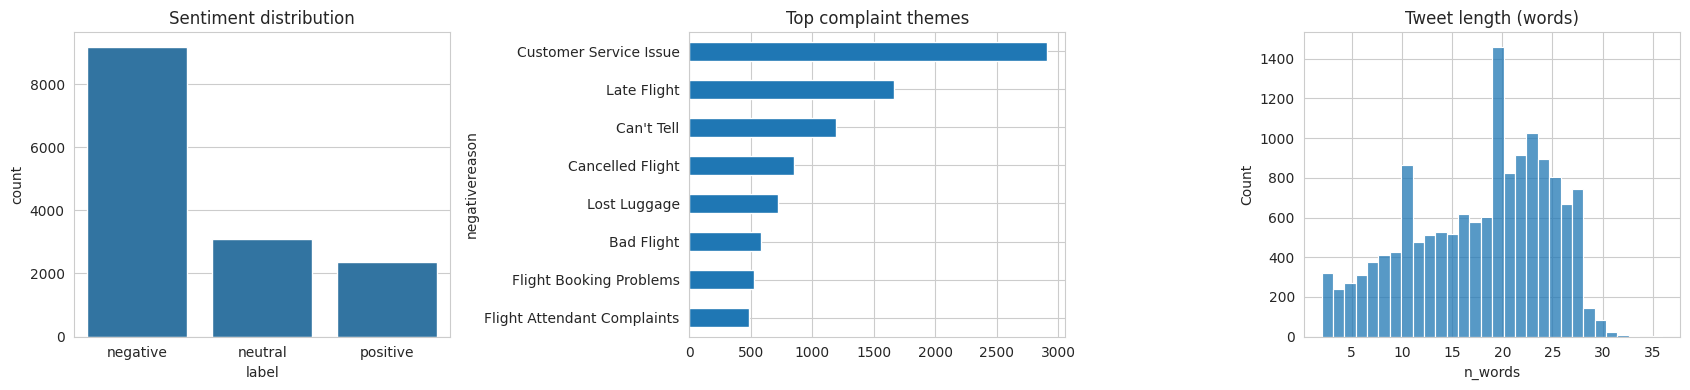

count    14640.000000
mean        17.653415
std          6.882259
min          2.000000
25%         12.000000
50%         19.000000
75%         23.000000
max         36.000000
Name: n_words, dtype: float64


In [ ]:
fig, ax = plt.subplots(1,3, figsize=(17,4))
sns.countplot(data=df, x='label', order=['negative','neutral','positive'], ax=ax[0]); ax[0].set_title('Sentiment distribution')
df['negativereason'].value_counts().head(8).plot.barh(ax=ax[1]); ax[1].set_title('Top complaint themes'); ax[1].invert_yaxis()
df['n_words'] = df['text'].str.split().str.len()
sns.histplot(df['n_words'], bins=30, ax=ax[2]); ax[2].set_title('Tweet length (words)')
plt.tight_layout(); plt.show()
print(df['n_words'].describe())

### 1.3 Text cleaning
We remove URLs, @mentions and extra symbols. The `#` sign is dropped but hashtag words are kept. Text is lower-cased. Mentions are removed because airline handles would otherwise dominate the vocabulary.

In [ ]:
def clean(t):
    t = re.sub(r'http\S+|www\.\S+', ' ', t)      # URLs
    t = re.sub(r'@\w+', ' ', t)                  # mentions
    t = t.replace('#', ' ')                       # keep hashtag word
    t = re.sub(r'[^A-Za-z0-9\s\'!?$]', ' ', t)  # symbols
    return re.sub(r'\s+', ' ', t).strip().lower()
df['clean'] = df['text'].apply(clean)
df[['text','clean']].head(5)

,text,clean
0,@VirginAmerica What @dhepburn said.,what said
1,@VirginAmerica plus you've added commercials t...,plus you've added commercials to the experienc...
2,@VirginAmerica I didn't today... Must mean I n...,i didn't today must mean i need to take anothe...
3,@VirginAmerica it's really aggressive to blast...,it's really aggressive to blast obnoxious ente...
4,@VirginAmerica and it's a really big bad thing...,and it's a really big bad thing about it


### 1.4 NLTK vs spaCy tokenisation, stop words and lemmatisation

In [ ]:
nlp = spacy.load('en_core_web_sm')
stop_nltk = set(stopwords.words('english'))
lem = WordNetLemmatizer()
sample = df.sample(2000, random_state=SEED)

# NLTK pipeline
t0 = time.time()
nltk_tok = [[w for w in word_tokenize(t) if w.isalpha()] for t in sample['clean']]
nltk_tok_nostop = [[w for w in toks if w not in stop_nltk] for toks in nltk_tok]
nltk_lem = [[lem.lemmatize(w) for w in toks] for toks in nltk_tok_nostop]
t_nltk = time.time()-t0

# spaCy pipeline
t0 = time.time()
docs = list(nlp.pipe(sample['clean'], batch_size=200))
sp_tok = [[t.text for t in d if t.is_alpha] for d in docs]
sp_nostop = [[t.text for t in d if t.is_alpha and not t.is_stop] for d in docs]
sp_lem = [[t.lemma_ for t in d if t.is_alpha and not t.is_stop] for d in docs]
t_spacy = time.time()-t0
print(f'NLTK {t_nltk:.1f}s | spaCy {t_spacy:.1f}s')

NLTK 0.2s | spaCy 5.1s


In [ ]:
ex = sample['clean'].iloc[3]
print('Text  :', ex)
print('NLTK  :', [lem.lemmatize(w) for w in word_tokenize(ex) if w.isalpha() and w not in stop_nltk])
print('spaCy :', [t.lemma_ for t in nlp(ex) if t.is_alpha and not t.is_stop])
# lemmatisation differences (NLTK lemmatises as nouns by default, so verbs like 'delayed' stay unchanged)
for w in ['delayed','cancelled','flying','lost','waiting']:
    print(w, '-> NLTK:', lem.lemmatize(w), '| spaCy:', nlp(w)[0].lemma_)

Text  : do they have to depart from washington d c ??
NLTK  : ['depart', 'washington', 'c']
spaCy : ['depart', 'washington', 'd', 'c']
delayed -> NLTK: delayed | spaCy: delay
cancelled -> NLTK: cancelled | spaCy: cancel
flying -> NLTK: flying | spaCy: fly
lost -> NLTK: lost | spaCy: lose
waiting -> NLTK: waiting | spaCy: wait


### 1.5 Named entity recognition (spaCy)

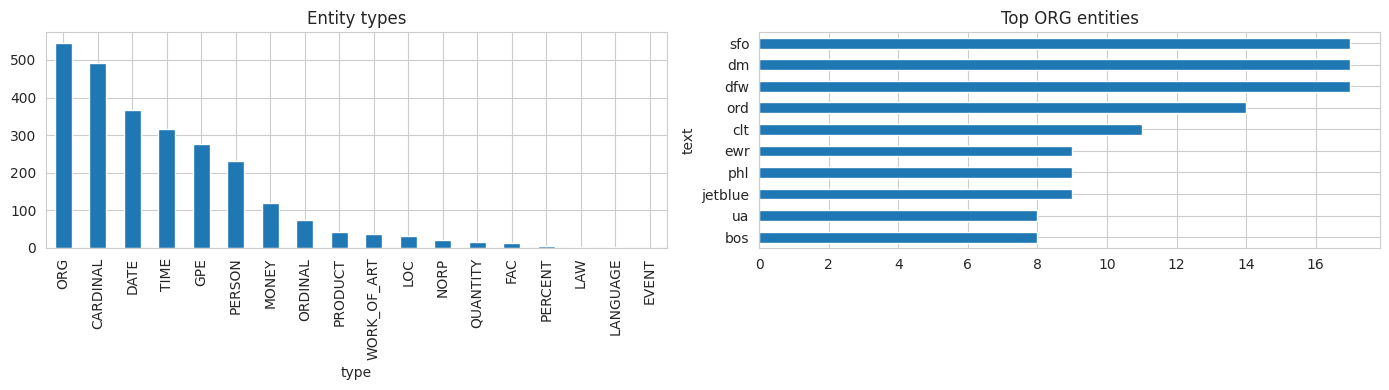

ORG ['EWR', 'USAirways', 'BDL', 'DCA', 'PHX']
GPE ['Washington', 'D.C.', 'Paris', 'Philly', 'Dallas']
DATE ['yesterday', 'today', '3472', 'the 5 days', 'today']
MONEY ['RockStar', '3322', 'just under $800', 'ticket,12h', 'meeting,7$']
TIME ['tonight', 'over 3 hours', 'an hour', 'http://t.co/UieSR3GHHO', '14 hours']


In [ ]:
ents = [(e.text, e.label_) for d in nlp.pipe(sample['text'].str.replace(r'@\w+','',regex=True), batch_size=200) for e in d.ents]
ent_df = pd.DataFrame(ents, columns=['text','type'])
fig, ax = plt.subplots(1,2, figsize=(14,4))
ent_df['type'].value_counts().plot.bar(ax=ax[0], title='Entity types')
ent_df[ent_df.type=='ORG']['text'].str.lower().value_counts().head(10).plot.barh(ax=ax[1], title='Top ORG entities'); ax[1].invert_yaxis()
plt.tight_layout(); plt.show()
for typ in ['ORG','GPE','DATE','MONEY','TIME']:
    print(typ, ent_df[ent_df.type==typ]['text'].head(5).tolist())

### 1.6 Token frequencies and word clouds

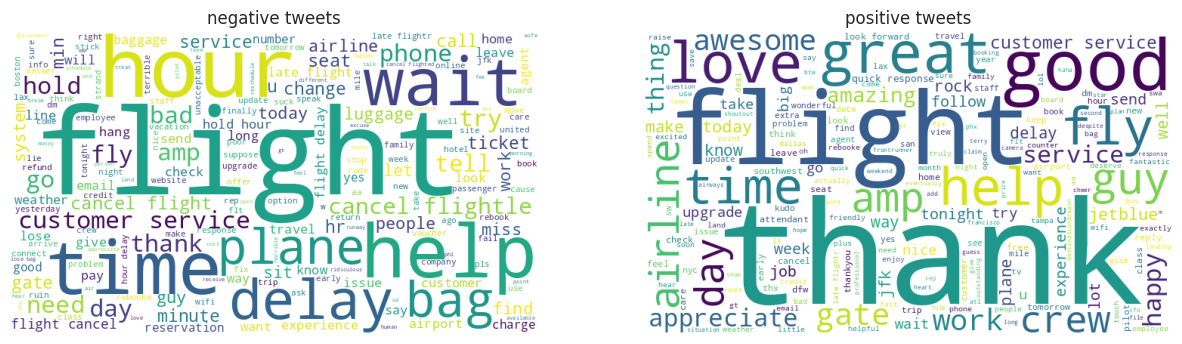

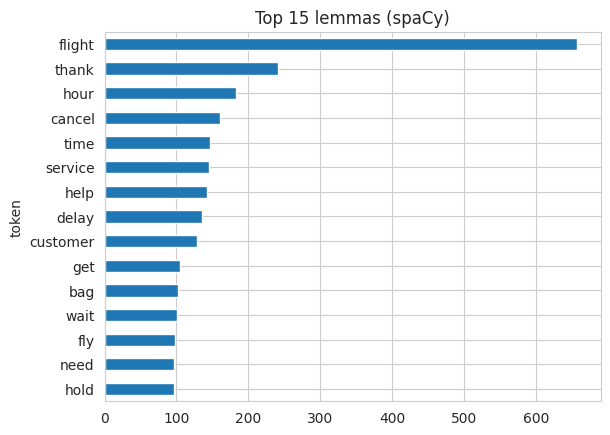

In [ ]:
from wordcloud import WordCloud
fig, ax = plt.subplots(1,2, figsize=(15,5))
for a, lab in zip(ax, ['negative','positive']):
    idx = sample['label'].values == lab
    toks = [w for toks, m in zip(sp_lem, idx) if m for w in toks]
    a.imshow(WordCloud(width=700, height=400, background_color='white').generate(' '.join(toks))); a.axis('off'); a.set_title(f'{lab} tweets')
plt.show()
top = Counter([w for t in sp_lem for w in t]).most_common(15)
pd.DataFrame(top, columns=['token','count']).set_index('token').plot.barh(title='Top 15 lemmas (spaCy)', legend=False).invert_yaxis()

### 1.7 NLTK vs spaCy comparison table

In [ ]:
flat = lambda L: [w for t in L for w in t]
cmp = pd.DataFrame({
 'Metric': ['Total tokens (alpha)','Vocabulary size (tokens)','Vocabulary after stop words + lemma','Processing time (s)','Entities detected'],
 'NLTK':  [len(flat(nltk_tok)), len(set(flat(nltk_tok))), len(set(flat(nltk_lem))), round(t_nltk,1), 'not supported'],
 'spaCy': [len(flat(sp_tok)),   len(set(flat(sp_tok))),   len(set(flat(sp_lem))),   round(t_spacy,1), len(ents)]})
cmp

,Metric,NLTK,spaCy
0,Total tokens (alpha),32258,32308.0
1,Vocabulary size (tokens),3862,3848.0
2,Vocabulary after stop words + lemma,3476,3003.0
3,Processing time (s),0.2,5.1
4,Entities detected,not supported,2594.0


**Reflection (write in your own words):** think about how removing stop words affects sentiment. Words such as *not*, *no* and *never* are stop words but flip sentiment. We test this next.

In [ ]:
# Stop-word experiment: keep vs remove (feeds into the Task 2 discussion)
tr, te = train_test_split(df, test_size=0.2, stratify=df['label'], random_state=SEED)
for name, sw in [('stop words KEPT', None), ('stop words REMOVED', 'english')]:
    v = TfidfVectorizer(stop_words=sw, ngram_range=(1,2), min_df=2)
    m = LogisticRegression(max_iter=1000).fit(v.fit_transform(tr['clean']), tr['label'])
    p = m.predict(v.transform(te['clean']))
    print(name, '| acc', round(accuracy_score(te['label'],p),4), '| macro-F1', round(precision_recall_fscore_support(te['label'],p,average='macro')[2],4))

stop words KEPT | acc 0.791 | macro-F1 0.7026
stop words REMOVED | acc 0.7657 | macro-F1 0.6665


## Task 2: Classical NLP Baseline (TF-IDF + Logistic Regression / Linear SVM)

In [ ]:
vec = TfidfVectorizer(ngram_range=(1,2), min_df=2, sublinear_tf=True)
Xtr, Xte = vec.fit_transform(tr['clean']), vec.transform(te['clean'])
models = {'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
          'Linear SVM': LinearSVC(class_weight='balanced')}
res, preds, times = [], {}, {}
for n, m in models.items():
    t0 = time.time(); m.fit(Xtr, tr['label']); times[n] = time.time()-t0
    p = m.predict(Xte); preds[n] = p
    pr, rc, f1, _ = precision_recall_fscore_support(te['label'], p, average='macro')
    res.append([n, accuracy_score(te['label'],p), pr, rc, f1, precision_recall_fscore_support(te['label'], p, average='weighted')[2], times[n]])
res_df = pd.DataFrame(res, columns=['Model','Accuracy','Macro-P','Macro-R','Macro-F1','Weighted-F1','Train time (s)']).round(4)
res_df

,Model,Accuracy,Macro-P,Macro-R,Macro-F1,Weighted-F1,Train time (s)
0,Logistic Regression,0.7886,0.7344,0.7458,0.7384,0.7925,4.5823
1,Linear SVM,0.7961,0.7481,0.7212,0.7331,0.7938,0.2589


              precision    recall  f1-score   support

    negative       0.89      0.84      0.87      1835
     neutral       0.59      0.69      0.64       620
    positive       0.73      0.70      0.71       473

    accuracy                           0.79      2928
   macro avg       0.73      0.75      0.74      2928
weighted avg       0.80      0.79      0.79      2928



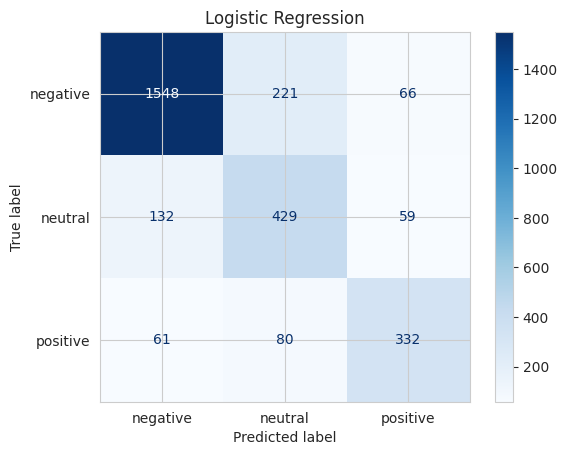

In [ ]:
best = 'Logistic Regression'
print(classification_report(te['label'], preds[best]))
ConfusionMatrixDisplay.from_predictions(te['label'], preds[best], cmap='Blues'); plt.title(best); plt.show()

### Misclassified examples and most important features

In [ ]:
err = te.assign(pred=preds[best])[te['label'].values != preds[best]]
pd.set_option('display.max_colwidth', 200)
err[['text','label','pred']].sample(6, random_state=1)   # choose 2 to explain in your report

,text,label,pred
420,@VirginAmerica is helping me step up my @Tinder game! #TinderTips #tinderchamp http://t.co/jBmVVha63A,neutral,negative
12042,@AmericanAir thanks for getting back to me. But I will find other airlines in the future.,negative,positive
587,@united mobile apps need construction from the ground up for each OS category. It's expensive to get right .,negative,neutral
11144,@USAirways No I got to Philly on Monday and got to my final destination South Carolina on Wednesday. Its not acceptable.,negative,neutral
7154,nope. RT @JetBlue: Our fleet's on fleek. http://t.co/9SHhTvIOTI,negative,neutral
6468,"@SouthwestAir bos to msp, msp to aus, aus to bos. Site doesn't seem to display fields for the middle trip when I add the 3rd.",negative,neutral


In [ ]:
lr = models[best]; fn = np.array(vec.get_feature_names_out())
for i, c in enumerate(lr.classes_):
    print(c.upper(), '->', fn[np.argsort(lr.coef_[i])[-10:]][::-1])

NEGATIVE -> ['not' 'no' 'delayed' 'hours' 'your' 'worst' 'why' 'cancelled' 'hour'
 'delay']
NEUTRAL -> ['can you' 'hi' 'is there' 'can' 'do you' 'any' 'do' 'need' 'dm' 'or']
POSITIVE -> ['great' 'thanks' 'awesome' 'love' 'amazing' 'thank' 'thx' 'best'
 'thank you' 'thanks for']


### Optional: NER-based features

In [ ]:
from scipy.sparse import hstack, csr_matrix
def ner_feats(texts):
    out = []
    for d in nlp.pipe(texts, batch_size=200):
        l = {e.label_ for e in d.ents}
        out.append([int('ORG' in l), int('GPE' in l), int('DATE' in l), int('MONEY' in l), int('TIME' in l)])
    return csr_matrix(np.array(out))
t0=time.time(); Ftr, Fte = ner_feats(tr['text']), ner_feats(te['text']); print('NER time', round(time.time()-t0,1),'s')
m2 = LogisticRegression(max_iter=1000, class_weight='balanced').fit(hstack([Xtr,Ftr]), tr['label'])
p2 = m2.predict(hstack([Xte,Fte]))
print('TF-IDF only macro-F1:', round(res_df.loc[0,'Macro-F1'],4), '| TF-IDF + NER macro-F1:', round(precision_recall_fscore_support(te['label'],p2,average='macro')[2],4))

NER time 54.0 s
TF-IDF only macro-F1: 0.7384 | TF-IDF + NER macro-F1: 0.7333


## Task 3: Semantic Embeddings (Sentence Transformers)
We use a **pretrained** model (`all-MiniLM-L6-v2`) because tweets are short and the dataset is small, which makes Word2Vec trained from scratch weak. Pretrained sentence embeddings capture meaning of whole tweets.

In [ ]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
st = SentenceTransformer('all-MiniLM-L6-v2')
emb_df = df.sample(3000, random_state=SEED).reset_index(drop=True)
emb = st.encode(emb_df['clean'].tolist(), show_progress_bar=True, batch_size=64)
emb.shape

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/47 [00:00<?, ?it/s]

(3000, 384)

In [ ]:
# Cosine similarity demo
pairs = [("my flight was delayed for hours","the plane left very late"),
         ("my flight was delayed for hours","great crew, loved the service"),
         ("lost my luggage","baggage never arrived")]
for a,b in pairs:
    print(round(float(cosine_similarity(st.encode([a]), st.encode([b]))[0][0]),3), '|', a, '<->', b)

0.525 | my flight was delayed for hours <-> the plane left very late
0.151 | my flight was delayed for hours <-> great crew, loved the service
0.621 | lost my luggage <-> baggage never arrived


In [ ]:
# Retrieval demo
def search(q, k=5):
    s = cosine_similarity(st.encode([q]), emb)[0]
    i = s.argsort()[::-1][:k]
    return pd.DataFrame({'score':s[i].round(3),'label':emb_df.loc[i,'label'].values,'tweet':emb_df.loc[i,'text'].values})
for q in ['delivery was late','customer service was unhelpful','lost luggage']:
    print('\nQUERY:', q); display(search(q))


QUERY: delivery was late


,score,label,tweet
0,0.581,positive,@AmericanAir thanks. Delivery status??
1,0.566,positive,"@AmericanAir yes, it says it should be deliver within 6 hours after pick up line."
2,0.565,negative,"@United ""delayed due to customer service"" Huh? http://t.co/XlTV5z6sT1"
3,0.555,negative,@united when is my plane coming? Been delayed for almost 7 hours. No plane.
4,0.554,negative,"@united Not sure what happened @ MSP yesterday, but VERY UNHAPPY my bag was not only delayed, but sat at MSP for 8 hrs b4 delivery @ 2:30 am"



QUERY: customer service was unhelpful


,score,label,tweet
0,0.694,negative,@USAirways your customer service is atrocious.
1,0.687,negative,@united your customer service is terrible
2,0.667,negative,@SouthwestAir I have never had such awful customer service and conflicting service. Outrageous.
3,0.620,negative,@united so much for being here to help. Very disappointed in your customer service.
4,0.615,negative,@SouthwestAir customer service is rude and bothered by our calls. Has no idea what is going on and sighed heavily on the phone. Unbelievable



QUERY: lost luggage


,score,label,tweet
0,0.679,negative,"@VirginAmerica lost my luggage 4 days ago on flight VX 112 from LAX to IAD &amp; I'm calling every day, no response.Please give me back my stuff"
1,0.643,negative,@USAirways now you don't know where my luggage is? Seriously?
2,0.637,negative,@SouthwestAir My luggage has still not been found. Luggage is not scanned until final destination. So no way of knowing where it is!
3,0.637,negative,@USAirways if you DM me we can take this offline. Would love more info on location of lost bags. Any help is appreciated.
4,0.633,negative,@AmericanAir westjet and your rep won't do anything about my lost luggage- which I never even checked with westjet because it was lost in


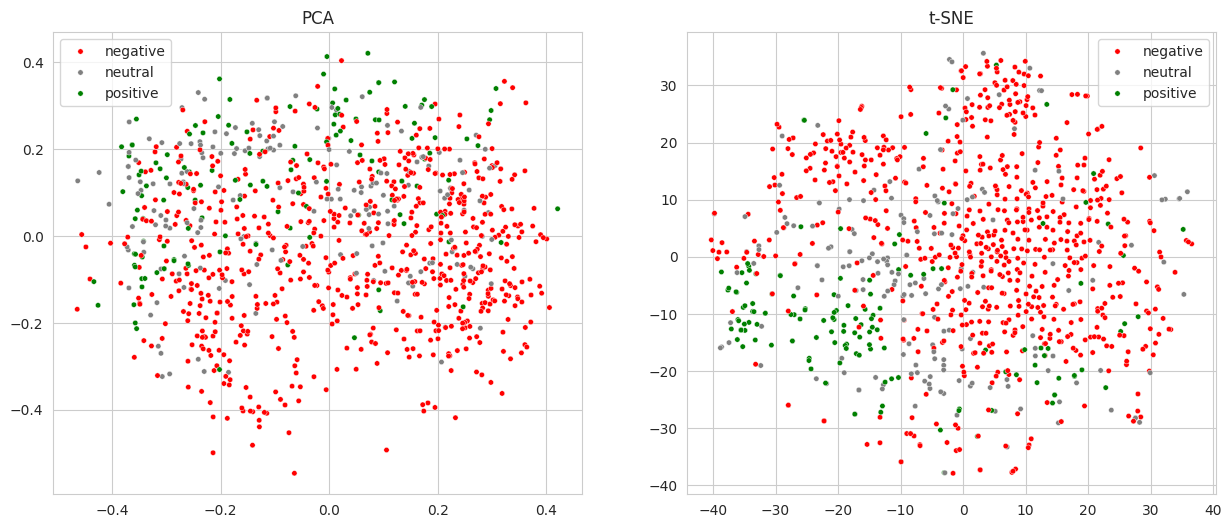

In [ ]:
# PCA and t-SNE
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
sub = emb_df.sample(1000, random_state=SEED).index
Z_pca = PCA(2, random_state=SEED).fit_transform(emb[sub])
Z_tsne = TSNE(2, random_state=SEED, perplexity=30, init='pca').fit_transform(emb[sub])
fig, ax = plt.subplots(1,2, figsize=(15,6))
for a, Z, t in zip(ax, [Z_pca, Z_tsne], ['PCA','t-SNE']):
    sns.scatterplot(x=Z[:,0], y=Z[:,1], hue=emb_df.loc[sub,'label'].values, palette={'negative':'red','neutral':'grey','positive':'green'}, s=15, ax=a); a.set_title(t)
plt.show()

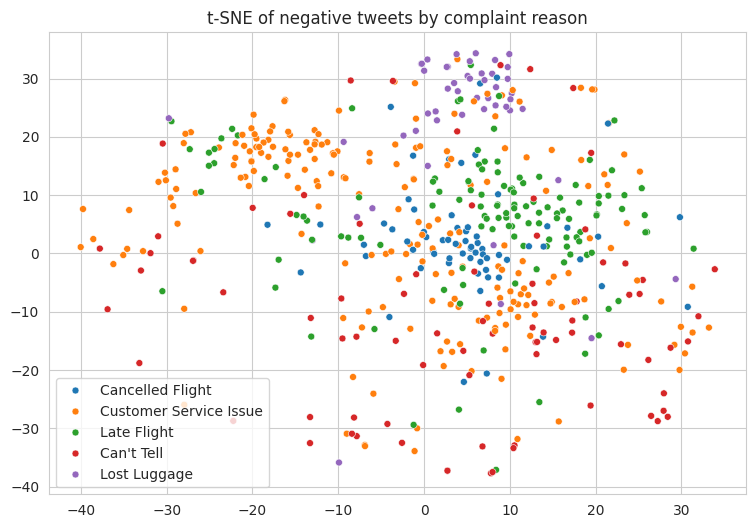

In [ ]:
# Colour by complaint reason (negative tweets only)
neg = emb_df.loc[sub][emb_df.loc[sub,'label']=='negative']
top_r = neg['negativereason'].value_counts().head(5).index
mask = emb_df.loc[sub,'negativereason'].isin(top_r).values
plt.figure(figsize=(9,6)); sns.scatterplot(x=Z_tsne[mask,0], y=Z_tsne[mask,1], hue=emb_df.loc[sub,'negativereason'].values[mask], s=25)
plt.title('t-SNE of negative tweets by complaint reason'); plt.show()

## Task 4: Fine-tuning DistilBERT
We train on 3,000 labelled tweets and evaluate on the **same test set** as Task 2 for a fair comparison. We also train the classical model on the same 3,000 tweets.

In [ ]:
!pip -q install transformers datasets accelerate
import torch
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
print('GPU:', torch.cuda.is_available())
labels = ['negative','neutral','positive']; l2i = {l:i for i,l in enumerate(labels)}
tr3k = tr.sample(3000, random_state=SEED)[['clean','label']]
te_s = te[['clean','label']]
tok = AutoTokenizer.from_pretrained('distilbert-base-uncased')
def prep(d):
    ds = Dataset.from_dict({'text': d['clean'].tolist(), 'label': d['label'].map(l2i).tolist()})
    return ds.map(lambda b: tok(b['text'], truncation=True, padding='max_length', max_length=64), batched=True)
ds_tr, ds_te = prep(tr3k), prep(te_s)
ds_tr

GPU: True


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2928 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 3000
})

In [ ]:
model = AutoModelForSequenceClassification.from_pretrained('distilbert-base-uncased', num_labels=3)
args = TrainingArguments(output_dir='out', num_train_epochs=3, per_device_train_batch_size=32, per_device_eval_batch_size=64,
                         learning_rate=5e-5, weight_decay=0.01, fp16=torch.cuda.is_available(), report_to='none', save_strategy='no', logging_steps=20)
trainer = Trainer(model=model, args=args, train_dataset=ds_tr)
t0 = time.time(); trainer.train(); t_bert = time.time()-t0
print(f'Training time: {t_bert:.0f}s')

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
20,0.867484
40,0.614732
60,0.472543
80,0.496533
100,0.449941
120,0.355281
140,0.350328
160,0.358867
180,0.312350
200,0.272063


Training time: 42s


              precision    recall  f1-score   support

    negative       0.87      0.92      0.89      1835
     neutral       0.68      0.58      0.63       620
    positive       0.76      0.72      0.74       473

    accuracy                           0.82      2928
   macro avg       0.77      0.74      0.75      2928
weighted avg       0.81      0.82      0.81      2928



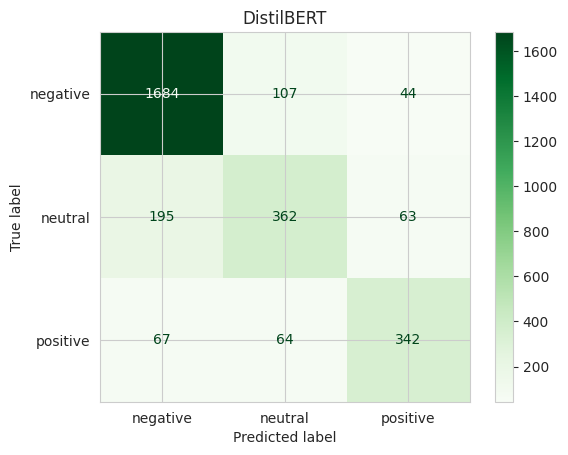

In [ ]:
out = trainer.predict(ds_te)
pb = out.predictions.argmax(1); yt = out.label_ids
print(classification_report(yt, pb, target_names=labels))
ConfusionMatrixDisplay.from_predictions(yt, pb, display_labels=labels, cmap='Greens'); plt.title('DistilBERT'); plt.show()

In [ ]:
# Fair comparison: classical model on the same 3,000 tweets
v3 = TfidfVectorizer(ngram_range=(1,2), min_df=2, sublinear_tf=True)
t0=time.time(); lr3 = LogisticRegression(max_iter=1000, class_weight='balanced').fit(v3.fit_transform(tr3k['clean']), tr3k['label']); t_lr3=time.time()-t0
p3 = lr3.predict(v3.transform(te_s['clean']))
def row(n,y,p,t,params):
    return [n, accuracy_score(y,p), *precision_recall_fscore_support(y,p,average='macro')[:3], precision_recall_fscore_support(y,p,average='weighted')[2], t, params]
y_true = te_s['label'].values; p_bert = np.array(labels)[pb]
final = pd.DataFrame([
  row('TF-IDF + LR (full train)', y_true, preds['Logistic Regression'], times['Logistic Regression'], f'{len(fn):,} features'),
  row('TF-IDF + LR (3k train)',   y_true, p3, t_lr3, 'sparse features'),
  row('DistilBERT (3k train)',    y_true, p_bert, t_bert, '66M parameters')],
  columns=['Model','Accuracy','Macro-P','Macro-R','Macro-F1','Weighted-F1','Train time (s)','Size']).round(4)
final

,Model,Accuracy,Macro-P,Macro-R,Macro-F1,Weighted-F1,Train time (s),Size
0,TF-IDF + LR (full train),0.7886,0.7344,0.7458,0.7384,0.7925,4.5823,"24,056 features"
1,TF-IDF + LR (3k train),0.7688,0.7113,0.7016,0.7058,0.7688,2.1667,sparse features
2,DistilBERT (3k train),0.8156,0.7687,0.7415,0.7535,0.8111,42.0872,66M parameters


In [ ]:
# Inference speed and error analysis
t0=time.time(); trainer.predict(ds_te); t_inf=time.time()-t0
t0=time.time(); lr3.predict(v3.transform(te_s['clean'])); t_inf_lr=time.time()-t0
print(f'Inference on {len(te_s)} tweets: DistilBERT {t_inf:.1f}s | LR {t_inf_lr:.2f}s')
errs = te.assign(bert=p_bert)[y_true != p_bert]
errs[['text','label','bert']].sample(6, random_state=2)

Inference on 2928 tweets: DistilBERT 3.5s | LR 0.27s


,text,label,bert
4057,@united thanks for not getting my BusinessFirst priority tagged bag onto my connecting flight at EWR despite a 2+ hour layover. Nice job,positive,negative
9388,@USAirways our flight was rebooked with you and we want to change our seats or upgrade to 1st class. Can you help? Phones are down.,negative,neutral
4218,@united who can tell me where they are?,negative,neutral
12003,@AmericanAir thanks for the info Is there a number I can call to speak to a person? It's going to take an hour to type it out,positive,neutral
12063,.@AmericanAir just disappointed with the Flight Booking Problems process and add’l fees to sit together on a more crowded flight. Not impressed so far :-/.,neutral,negative
3034,"@united Will do, cheers",neutral,positive


In [ ]:
# Fairness-style check: performance per airline (use in Task 5)
chk = te.assign(bert=p_bert, lr=preds['Logistic Regression'])
chk.groupby('airline').apply(lambda g: pd.Series({'n':len(g),'LR acc':accuracy_score(g.label,g.lr),'BERT acc':accuracy_score(g.label,g.bert)})).round(3)

/tmp/ipykernel_11765/2150122247.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  chk.groupby('airline').apply(lambda g: pd.Series({'n':len(g),'LR acc':accuracy_score(g.label,g.lr),'BERT acc':accuracy_score(g.label,g.bert)})).round(3)


,n,LR acc,BERT acc
airline,,,
American,535.0,0.822,0.860
Delta,456.0,0.776,0.789
Southwest,506.0,0.749,0.773
US Airways,565.0,0.823,0.867
United,774.0,0.789,0.800
Virgin America,92.0,0.652,0.739


In [ ]:
# Urgent-complaint check: how many truly negative tweets are missed? (use in Task 5)
for n, p in [('LR', preds['Logistic Regression']), ('DistilBERT', p_bert)]:
    neg_mask = y_true=='negative'
    print(n, 'negative recall:', round((p[neg_mask]=='negative').mean(),3), '| negatives labelled positive:', int((p[neg_mask]=='positive').sum()))

LR negative recall: 0.844 | negatives labelled positive: 66
DistilBERT negative recall: 0.918 | negatives labelled positive: 44


In [ ]:
import os
# Install Chromium and other dependencies needed for pyppeteer/pdf generation
!apt-get update -qy
!apt-get install -y -q chromium-codecs-ffmpeg-extra kanjifonts-gnu debian-keyring debian-archive-keyring > /dev/null
!pip install -q nbconvert[webpdf]

# We will export the current notebook state.
# Since the active Colab notebook isn't saved directly to disk automatically,
# we will attempt to find or download it, or guide you to download the .ipynb first if needed.
# As a robust alternative, we will write a script to generate a beautiful summarized PDF report
# using ReportLab containing all our key tables, metrics, and figures saved locally.

print('Dependencies installed successfully! Generating summary PDF report...')

Hit:1 https://cli.github.com/packages stable InRelease
Get:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease [1,578 B]
Get:4 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:5 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Hit:6 http://archive.ubuntu.com/ubuntu noble InRelease
Get:7 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  Packages [1,886 kB]
Get:8 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:9 https://r2u.stat.illinois.edu/ubuntu noble/main amd64 Packages [3,045 kB]
Get:10 https://r2u.stat.illinois.edu/ubuntu noble/main all Packages [10.3 MB]
Get:11 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:12 http://security.ubuntu.com/ubuntu noble-security/main amd64 Packages [1,323 kB]
Get:13 http://archive.ubuntu.com/ubuntu noble-backpor

In [ ]:
from reportlab.lib.pagesizes import letter
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib import colors
import matplotlib.pyplot as plt

# Save a combined visualization of our findings for the PDF
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# 1. Class Distribution
sns.countplot(data=df, x='label', order=['negative','neutral','positive'], ax=ax[0])
ax[0].set_title('Sentiment Distribution')

# 2. Performance Comparison Bar Chart
models_comparison = final.copy()
sns.barplot(data=models_comparison, x='Model', y='Accuracy', ax=ax[1], palette='Blues_d')
ax[1].set_title('Model Accuracy Comparison')
ax[1].set_xticklabels(ax[1].get_xticklabels(), rotation=15, ha='right')

plt.tight_layout()
plt.savefig('pdf_summary_plot.png', dpi=200)
plt.close()

# Build the PDF
pdf_path = "NLP_Task_Outputs_Report.pdf"
doc = SimpleDocTemplate(pdf_path, pagesize=letter, rightMargin=30, leftMargin=30, topMargin=30, bottomMargin=30)
styles = getSampleStyleSheet()

story = []

# Title
story.append(Paragraph("<b>NLP Assignment: Airline Sentiment Analysis Report</b>", styles['Title']))
story.append(Spacer(1, 20))

# Task 1 Section
story.append(Paragraph("<b>1. Preprocessing & Exploratory Data Analysis</b>", styles['Heading2']))
story.append(Paragraph(f"Total tweets analyzed: {df.shape[0]} across {df['airline'].nunique()} airlines.", styles['Normal']))
story.append(Spacer(1, 10))

# Add comparison table
story.append(Paragraph("<b>NLTK vs spaCy Tokenizer Comparison:</b>", styles['Heading3']))
# Convert comparison dataframe to list of lists for ReportLab
orig_cols = cmp.columns.tolist()
compare_data = [orig_cols] + cmp.values.tolist()
t1 = Table(compare_data, colWidths=[200, 100, 100])
t1.setStyle(TableStyle([
    ('BACKGROUND', (0,0), (-1,0), colors.grey),
    ('TEXTCOLOR', (0,0), (-1,0), colors.whitesmoke),
    ('ALIGN', (0,0), (-1,-1), 'CENTER'),
    ('FONTNAME', (0,0), (-1,0), 'Helvetica-Bold'),
    ('BOTTOMPADDING', (0,0), (-1,0), 6),
    ('BACKGROUND', (0,1), (-1,-1), colors.beige),
    ('GRID', (0,0), (-1,-1), 1, colors.black)
]))
story.append(t1)
story.append(Spacer(1, 15))

# Task 2 & 4 Model Performance
story.append(Paragraph("<b>2. Sentiment Model Benchmark Results</b>", styles['Heading2']))
final_data = [final.columns.tolist()] + final.values.tolist()
t2 = Table(final_data, colWidths=[150, 60, 60, 60, 60, 60, 60, 100])
t2.setStyle(TableStyle([
    ('BACKGROUND', (0,0), (-1,0), colors.navy),
    ('TEXTCOLOR', (0,0), (-1,0), colors.whitesmoke),
    ('ALIGN', (0,0), (-1,-1), 'CENTER'),
    ('FONTNAME', (0,0), (-1,0), 'Helvetica-Bold'),
    ('BOTTOMPADDING', (0,0), (-1,0), 6),
    ('GRID', (0,0), (-1,-1), 1, colors.black),
    ('FONTSIZE', (0,0), (-1,-1), 8)
]))
story.append(t2)
story.append(Spacer(1, 20))

# Add Plot Image
story.append(Paragraph("<b>Key Visualizations:</b>", styles['Heading3']))
story.append(Image('pdf_summary_plot.png', width=500, height=210))

doc.build(story)
print(f"PDF report generated successfully: {pdf_path}")

# Download the file to user's local machine
from google.colab import files
files.download(pdf_path)

## Appendix notes for the report
- Dataset: Crowdflower (2015) *Twitter US Airline Sentiment*, Kaggle. Add the full Harvard reference and link.
- Save this notebook to GitHub or Drive and link it in your appendix.